# 03 · Engenharia de Features

## Estratégia de previsão
- **Objetivo:** prever as vendas diárias de cada loja × item nos **30 dias** seguintes
  a uma data de corte, agregadas em **1ª quinzena (dias 1–15)** e **2ª quinzena (dias 16–30)**.
- **Previsão direta:** um modelo para cada horizonte (h = 1 … 30). Cada previsão é
  independente — sem acúmulo de erro, como ocorreria numa previsão recursiva.
- **Múltiplos cortes semanais:** simulamos 8 "segundas-feiras" no passado
  (24/abr a 12/jun/2017) para gerar exemplos de treino; **17/jul** é o corte de validação
  (alvo: 17/jul a 15/ago).
- **Sem vazamento de dados:** features usam apenas informação anterior ao corte, e os
  alvos de treino terminam antes do período de validação.

## Linha do tempo
| Corte | Histórico (features) | Alvo (30 dias) | Uso |
|---|---|---|---|
| 24/abr … 12/jun (8 segundas) | até 112 dias antes do corte | 30 dias após o corte | Treino |
| 17/jul | 27/mar → 16/jul | 17/jul → 15/ago | Validação |

## Tratamentos
- Dias sem venda registrados como **zero** (demanda intermitente).
- Alvo em escala **log(1 + vendas)**, a mesma da métrica oficial NWRMSLE.

## 1. Setup e carga
Carregamos as vendas de 2017 e os cadastros de itens e lojas, e importamos as
funções de `src/features.py`, onde está toda a lógica de construção das features.

In [1]:
import sys
sys.path.append("..")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_processed
from src.features import build_wide, build_dataset, N_HORIZONS

PROC = Path("../data/processed")
FIG = Path("../reports/figures")

data = load_processed()
train, items, stores = data["train_2017"], data["items"], data["stores"]
del data
print(train.shape)

(23808261, 5)


## 2. Matriz completa loja × item × dia
Transformamos a tabela "longa" (uma linha por venda registrada) em uma **matriz**:
cada linha é um par loja × item e cada coluna é um dia de 2017.
Os dias sem registro de venda passam a valer **zero** — resolvendo a demanda esparsa
identificada na EDA. As vendas já ficam em escala **log(1 + vendas)**.

In [2]:
sales, promo = build_wide(train)
del train  # libera memória: daqui em diante usamos só as matrizes

print(f"Matriz: {sales.shape[0]:,} pares loja × item  ×  {sales.shape[1]} dias")
print(f"Período: {sales.columns.min():%d/%m/%Y} a {sales.columns.max():%d/%m/%Y}")
print(f"Células com venda: {(sales.values > 0).mean():.1%}  |  sem venda (zero): {(sales.values == 0).mean():.1%}")
print(f"Memória: vendas {sales.memory_usage().sum() / 1e6:.0f} MB  |  promoções {promo.memory_usage().sum() / 1e6:.0f} MB")

Matriz: 167,515 pares loja × item  ×  227 dias
Período: 01/01/2017 a 15/08/2017
Células com venda: 62.6%  |  sem venda (zero): 37.4%
Memória: vendas 153 MB  |  promoções 39 MB


## 3. Cortes de treino e validação
- **Treino:** 8 segundas-feiras, de 24/abr a 12/jun/2017.
- **Validação:** 17/jul/2017 (alvo de 17/jul a 15/ago).

Antes de gerar os dados, **checamos automaticamente que não há vazamento**:
o último dia de alvo do treino precisa ser anterior ao corte de validação, e o
histórico de 112 dias do primeiro corte precisa existir nos dados.

In [3]:
train_cutoffs = pd.date_range("2017-04-24", "2017-06-12", freq="7D")  # 8 segundas-feiras
val_cutoff = pd.Timestamp("2017-07-17")

# Checagens de vazamento e de histórico suficiente
last_train_target = train_cutoffs[-1] + pd.Timedelta(days=N_HORIZONS - 1)
first_history_day = train_cutoffs[0] - pd.Timedelta(days=112)
assert last_train_target < val_cutoff, "Alvo de treino invade o período de validação!"
assert first_history_day >= sales.columns.min(), "Histórico insuficiente para o 1º corte!"

print("Cortes de treino:", ", ".join(d.strftime("%d/%m") for d in train_cutoffs))
print(f"Último alvo de treino: {last_train_target:%d/%m}  <  corte de validação: {val_cutoff:%d/%m}  ✔")

df_train = build_dataset(sales, promo, train_cutoffs, items, stores)
df_val = build_dataset(sales, promo, [val_cutoff], items, stores)

print(f"Treino: {df_train.shape[0]:,} linhas × {df_train.shape[1]} colunas")
print(f"Validação: {df_val.shape[0]:,} linhas × {df_val.shape[1]} colunas")
print(f"Memória do treino: {df_train.memory_usage(deep=True).sum() / 1e9:.2f} GB")

Cortes de treino: 24/04, 01/05, 08/05, 15/05, 22/05, 29/05, 05/06, 12/06
Último alvo de treino: 11/07  <  corte de validação: 17/07  ✔
Treino: 1,340,120 linhas × 100 colunas
Validação: 167,515 linhas × 100 colunas
Memória do treino: 0.52 GB


### 💡 Resumo da base de modelagem
- **167.515 pares loja × item** acompanhados diariamente por 227 dias.
- **37,4% das células (~14 milhões) são dias sem venda**, agora explicitamente
  registrados como zero — sem isso, o modelo veria apenas os dias "bons" e
  superestimaria a demanda.
- **Treino:** 1.340.120 linhas (8 cortes × 167.515 pares) · **Validação:** 167.515 linhas.
- **100 colunas:** 61 features de histórico, padrão semanal, intermitência e promoção,
  7 atributos fixos, 30 alvos (`y_d1` … `y_d30`) e identificadores.
- ✔ **Sem vazamento:** o último alvo de treino (11/07) é anterior ao corte de validação (17/07).

## 4. Quanto o histórico explica o futuro, por horizonte?
Antes de modelar, medimos a **correlação** entre médias históricas (7, 28 e 112 dias)
e a venda real em cada dia à frente (h = 1 … 30), no corte de validação.
Esperamos que a previsibilidade **caia com o horizonte** — e que médias mais longas
sejam mais úteis para prever mais longe.

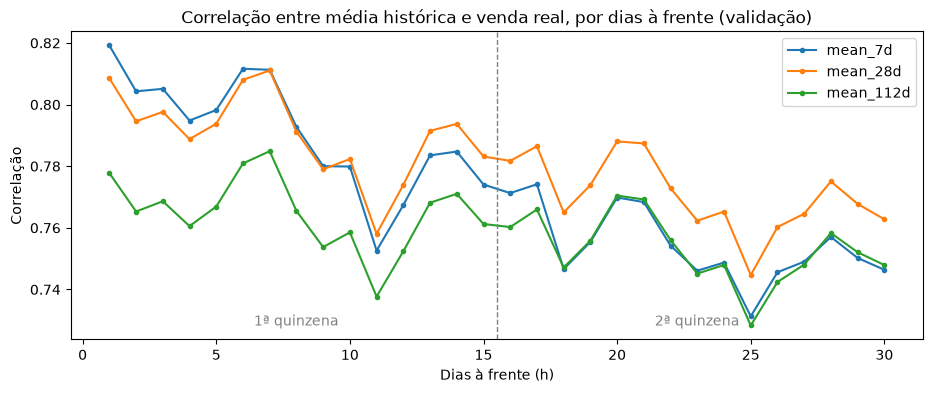

,mean_7d,mean_28d,mean_112d
1ª quinzena,0.791,0.790,0.765
2ª quinzena,0.754,0.771,0.753


In [4]:
feats = ["mean_7d", "mean_28d", "mean_112d"]
corr = pd.DataFrame(
    {f: [df_val[f].corr(df_val[f"y_d{h}"]) for h in range(1, N_HORIZONS + 1)] for f in feats},
    index=pd.RangeIndex(1, N_HORIZONS + 1, name="h"),
)

ax = corr.plot(figsize=(11, 4), marker="o", ms=3)
ax.axvline(15.5, color="gray", ls="--", lw=1)
ax.text(8, corr.values.min(), "1ª quinzena", ha="center", color="gray")
ax.text(23, corr.values.min(), "2ª quinzena", ha="center", color="gray")
ax.set(title="Correlação entre média histórica e venda real, por dias à frente (validação)",
       xlabel="Dias à frente (h)", ylabel="Correlação")
plt.savefig(FIG / "03_correlacao_horizonte.png", dpi=120, bbox_inches="tight")
plt.show()

quinzena = np.where(corr.index <= 15, "1ª quinzena", "2ª quinzena")
corr.groupby(quinzena).mean().round(3)

### 💡 Insights — Previsibilidade por horizonte

**O que os dados mostram**
1. **O histórico já explica muito da demanda:** a correlação entre médias simples e a
   venda real fica entre **0,73 e 0,82** em todos os 30 dias. Um *baseline* bem feito
   será competitivo — o LightGBM precisa superá-lo para justificar a complexidade.
2. **A previsibilidade cai com o horizonte, mas de forma moderada:** de ~0,82 no dia 1
   para ~0,75 no dia 30. A **2ª quinzena é mais difícil**, mas continua bastante previsível.
3. **A "memória ideal" muda com o horizonte:**
   - **1ª semana:** a média dos **últimos 7 dias** é a melhor referência (o passado
     recente pesa mais);
   - **A partir do 8º dia e em toda a 2ª quinzena:** a média de **28 dias** passa a
     ser a melhor — prever mais longe pede uma visão mais estável;
   - A média de **112 dias** é sempre a pior: é antiga demais e não acompanha
     mudanças de tendência.
4. **O padrão semanal aparece até na previsibilidade:** como o corte é uma segunda-feira,
   os vales em **h = 4, 11, 18 e 25 são quintas-feiras** — o dia mais fraco e mais
   irregular (seção 4 da EDA) — e os picos em **h = 6–7, 13–14, 20–21 e 27–28 são fins
   de semana**, quando a demanda é maior e mais estável.

**Implicações**
- **Para o modelo:** combinar janelas curtas e longas e usar as médias **por dia da
  semana** — é exatamente o que as features construídas fazem.
- **Para a gestão:** previsões para quintas-feiras e para a 2ª quinzena terão
  **maior margem de erro** e pedem **estoque de segurança proporcionalmente maior**;
  fins de semana, apesar do volume alto, são os dias **mais previsíveis**.

## 5. Salvar a base de modelagem
As tabelas de treino e validação são salvas em Parquet e serão o ponto de partida
do notebook `04_modelagem`.

In [5]:
df_train.to_parquet(PROC / "features_train.parquet", index=False)
df_val.to_parquet(PROC / "features_val.parquet", index=False)
print(sorted(p.name for p in PROC.glob("features_*.parquet")))

['features_train.parquet', 'features_val.parquet']
